# Supplementary Figures S15 and S17: new-edge decomposition and community structure

From 5_GlobalCitationNetwork_inclusionfragmentation. Supplementary Fig. S15: share of new positive and negative edges between existing and new countries. Supplementary Fig. S17: within-community positive and between-community negative connection probability for the 28 countries of the positive network in 2000.

It reads its input from the data folder (`path2data`). The figures are saved in the `figures` folder.

In [1]:
import os
import json
import gzip
import itertools
from itertools import chain
from collections import defaultdict
import pandas as pd
import numpy as np
import networkx as nx

import scipy.sparse as spsparse
import scipy.stats as spstats

from statsmodels.stats.multitest import multipletests as holm
import statsmodels.api as sm

import matplotlib.pylab as plt
import matplotlib.gridspec as gridspec
import matplotlib.transforms as mtransforms
import seaborn as sns

# set this path to where the processed data (Source Data) is stored:
path2sourcedata = "Source Data"
# when the notebook is run from the code folder, the Source Data folder is one level up
if not os.path.exists(path2sourcedata):
    path2sourcedata = os.path.join("..", "Source Data")

# the processed input data are in the data folder, next to the Source Data folder
path2data = os.path.join(os.path.dirname(os.path.abspath(path2sourcedata)), 'data')

# the regenerated figures are saved in the figures folder
path2figures = os.path.join(os.path.dirname(os.path.abspath(path2sourcedata)), 'figures')
os.makedirs(path2figures, exist_ok=True)

In [2]:
# Country counts per year for four conditions

def get_yearly_net(publim, syear=1990, eyear=2017):
    country_auc_df = pd.read_csv(os.path.join(path2data, 'oa_countrycites_nosameorg_auc.csv.gz'))
    country_auc_df['Zscore'] = (country_auc_df['AUC'] - 0.5) / np.sqrt(country_auc_df['Cov'])
    country_auc_df = country_auc_df[country_auc_df['N'] >= publim].reset_index(drop=True)
    # one-sided test in the direction of the observed preference: H1 is AUC > 0.5 (over-citation)
    # when Z > 0, and AUC < 0.5 (under-citation) when Z < 0
    country_auc_df['pvalue'] = spstats.norm.sf(np.abs(country_auc_df['Zscore'].values))

    def reject_holm(pvalues):
        reject, _, _, _ = holm(pvalues, alpha=0.01, method='hs', is_sorted=False, returnsorted=False)
        return reject

    country_auc_df['Significant'] = country_auc_df.groupby('CitedYear')['pvalue'].transform(reject_holm)

    # eSign: 1 = significant positive, -1 = significant negative, 0 = not significant
    country_auc_df['eSign'] = 0
    country_auc_df.loc[(country_auc_df['Significant'] == True) & (country_auc_df['Zscore'] > 0), 'eSign'] = 1
    country_auc_df.loc[(country_auc_df['Significant'] == True) & (country_auc_df['Zscore'] < 0), 'eSign'] = -1

    net = country_auc_df[country_auc_df['CitingCountry'] != country_auc_df['CitedCountry']]
    net = net[(net['CitedYear'] >= syear) & (net['CitedYear'] <= eyear)].copy()

    return net

def count_by_year(net, esign_filter=None, esign_min=None):
    
    """Cumulative network: for each year Y, 
    keep most recent eSign per (Citing, Cited) pair,
    then count unique countries."""
    
    years = sorted(net['CitedYear'].unique())
    results = []
    for y in years:
        cumnet = (net[net['CitedYear'] <= y]
                  .sort_values('CitedYear')
                  .drop_duplicates(subset=['CitingCountry', 'CitedCountry'], keep='last'))
        if esign_filter is not None:
            cumnet = cumnet[cumnet['eSign'] == esign_filter]
        elif esign_min is not None:
            cumnet = cumnet[cumnet['eSign'] >= esign_min]
        countries = set(cumnet['CitingCountry']).union(set(cumnet['CitedCountry']))
        results.append({'Year': int(y), 'n_countries': len(countries)})
    return pd.DataFrame(results)

yearly50 = get_yearly_net(50)
yearly2  = get_yearly_net(2)

c1 = count_by_year(yearly50, esign_filter=1).rename(columns={'n_countries': 'publim50_eSign_pos'})
c2 = count_by_year(yearly50, esign_min=0).rename(columns={'n_countries': 'publim50_eSign_nonneg'})
c3 = count_by_year(yearly50).rename(columns={'n_countries': 'publim50_all'})
c4 = count_by_year(yearly2).rename(columns={'n_countries': 'publim2_all'})

yearly_counts = c1.merge(c2, on='Year').merge(c3, on='Year').merge(c4, on='Year')
yearly_counts

,Year,publim50_eSign_pos,publim50_eSign_nonneg,publim50_all,publim2_all
0,1990,8,97,97,182
1,1991,9,100,100,190
2,1992,9,101,101,197
3,1993,12,104,104,202
4,1994,12,108,108,206
5,1995,17,113,113,209
6,1996,16,119,119,209
7,1997,18,124,124,210
8,1998,17,133,133,210
9,1999,18,137,138,213


## Supplementary Fig. S15: dynamic new-edge decomposition

In [3]:
# Dynamic new-edge decomposition
# "Existing" at year Y = countries currently in that signed network up to Y-1
#   (a country can re-enter as "new" if all its edges in that network flipped away)
# New edges at year Y  = edges entering the positive/negative network for the first time in Y
# EE — both endpoints in existing signed network; Mixed — one new; NN — both new
#
# FIX: classify() uses sign-specific existing sets, not the union.
# Without this, a country that exited the positive network but remains in the negative
# network is still counted as "existing" for positive-edge classification, hiding NN edges.

base = (yearly50[yearly50['CitedYear'] <= 1990]
        .sort_values('CitedYear')
        .drop_duplicates(subset=['CitingCountry', 'CitedCountry'], keep='last'))
base_pos = base[base['eSign'] ==  1]
base_neg = base[base['eSign'] == -1]

existing_pos_countries = set(base_pos['CitingCountry']).union(base_pos['CitedCountry'])
existing_neg_countries = set(base_neg['CitingCountry']).union(base_neg['CitedCountry'])
existing_countries     = existing_pos_countries.union(existing_neg_countries)

prev_pairs_pos = set(zip(base_pos['CitingCountry'], base_pos['CitedCountry']))
prev_pairs_neg = set(zip(base_neg['CitingCountry'], base_neg['CitedCountry']))

results_new = []

for y in range(1991, 2018):
    
    cumnet = (yearly50[yearly50['CitedYear'] <= y]
              .sort_values('CitedYear')
              .drop_duplicates(subset=['CitingCountry', 'CitedCountry'], keep='last'))

    curr_pos = cumnet[cumnet['eSign'] ==  1]
    curr_neg = cumnet[cumnet['eSign'] == -1]

    curr_pos_countries = set(curr_pos['CitingCountry']).union(curr_pos['CitedCountry'])
    curr_neg_countries = set(curr_neg['CitingCountry']).union(curr_neg['CitedCountry'])
    curr_signed        = curr_pos_countries.union(curr_neg_countries)
    new_countries      = curr_signed - existing_countries

    curr_pairs_pos = set(zip(curr_pos['CitingCountry'], curr_pos['CitedCountry']))
    curr_pairs_neg = set(zip(curr_neg['CitingCountry'], curr_neg['CitedCountry']))

    new_pairs_pos = curr_pairs_pos - prev_pairs_pos
    new_pairs_neg = curr_pairs_neg - prev_pairs_neg

    def classify(new_pairs, df, existing_set):
        if not new_pairs:
            return 0, 0, 0, 0
        mask = pd.Series(
            [p in new_pairs for p in zip(df['CitingCountry'], df['CitedCountry'])],
            index=df.index
        )
        e = df[mask]
        citing_e = e['CitingCountry'].isin(existing_set)
        cited_e  = e['CitedCountry'].isin(existing_set)
        ee    = int(( citing_e &  cited_e).sum())
        mixed = int(( citing_e ^  cited_e).sum())
        nn    = int((~citing_e & ~cited_e).sum())
        return ee, mixed, nn, len(e)

    ee_pos, mx_pos, nn_pos, tot_pos = classify(new_pairs_pos, curr_pos, existing_pos_countries)
    ee_neg, mx_neg, nn_neg, tot_neg = classify(new_pairs_neg, curr_neg, existing_neg_countries)

    def pct(n, d): return round(n / d * 100, 1) if d > 0 else np.nan

    results_new.append({
        'Year':                            y,
        'Existing positive countries':     len(existing_pos_countries),
        'Existing negative countries':     len(existing_neg_countries),
        'Existing countries (union)':      len(existing_countries),
        'New countries':                   len(new_countries),
        'New EE positive':                 ee_pos,
        'New Mixed positive':              mx_pos,
        'New NN positive':                 nn_pos,
        'Total new positive':              tot_pos,
        'EE share of new positive (%)':    pct(ee_pos, tot_pos),
        'Mixed share of new positive (%)': pct(mx_pos, tot_pos),
        'NN share of new positive (%)':    pct(nn_pos, tot_pos),
        'New EE negative':                 ee_neg,
        'New Mixed negative':              mx_neg,
        'New NN negative':                 nn_neg,
        'Total new negative':              tot_neg,
        'EE share of new negative (%)':    pct(ee_neg, tot_neg),
        'Mixed share of new negative (%)': pct(mx_neg, tot_neg),
        'NN share of new negative (%)':    pct(nn_neg, tot_neg),
        'Countries (positive)':            len(curr_pos_countries),
        'Countries (negative)':            len(curr_neg_countries),
    })

    prev_pairs_pos         = curr_pairs_pos
    prev_pairs_neg         = curr_pairs_neg
    existing_pos_countries = curr_pos_countries
    existing_neg_countries = curr_neg_countries
    existing_countries     = curr_signed

new_edge_decomp = pd.DataFrame(results_new)
new_edge_decomp


,Year,Existing positive countries,Existing negative countries,Existing countries (union),New countries,New EE positive,New Mixed positive,New NN positive,Total new positive,EE share of new positive (%),...,NN share of new positive (%),New EE negative,New Mixed negative,New NN negative,Total new negative,EE share of new negative (%),Mixed share of new negative (%),NN share of new negative (%),Countries (positive),Countries (negative)
0,1991,8,43,44,4,0,1,0,1,0.0,...,0.0,13,9,0,22,59.1,40.9,0.0,9,44
1,1992,9,44,44,5,1,0,0,1,100.0,...,0.0,34,5,0,39,87.2,12.8,0.0,9,47
2,1993,9,47,47,6,3,3,0,6,50.0,...,0.0,33,5,0,38,86.8,13.2,0.0,12,46
3,1994,12,46,47,8,0,2,0,2,0.0,...,0.0,39,9,0,48,81.2,18.8,0.0,12,52
4,1995,12,52,53,3,0,6,0,6,0.0,...,0.0,35,2,0,37,94.6,5.4,0.0,17,51
5,1996,17,51,52,6,1,0,0,1,100.0,...,0.0,42,7,0,49,85.7,14.3,0.0,16,54
6,1997,16,54,54,9,2,4,0,6,33.3,...,0.0,53,8,0,61,86.9,13.1,0.0,18,59
7,1998,18,59,60,6,1,2,0,3,33.3,...,0.0,35,5,0,40,87.5,12.5,0.0,17,60
8,1999,17,60,61,11,1,2,0,3,33.3,...,0.0,51,14,0,65,78.5,21.5,0.0,18,64
9,2000,18,64,66,8,3,6,3,12,25.0,...,25.0,51,8,0,59,86.4,13.6,0.0,28,66


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


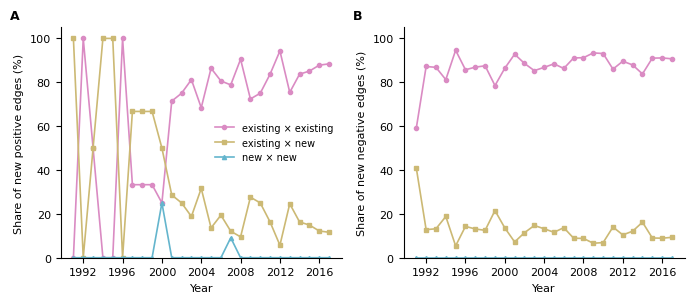

In [4]:
# plot dynamic decomposition

cm = 1/2.54
pal = sns.color_palette('deep')
c_ee, c_mixed, c_nn = pal[-4], pal[-2], pal[-1]

fig, axes = plt.subplots(1, 2, figsize=(17.8*cm, 8*cm))
ax1, ax2 = axes

for ax, label in zip(axes, ['A', 'B']):
    ax.text(-0.18, 1.08, label, transform=ax.transAxes,
            fontsize=9, fontweight='bold', va='top', ha='left')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.tick_params(axis='both', labelsize=8)
    ax.xaxis.set_major_locator(plt.MultipleLocator(4))
    ax.tick_params(axis='x', rotation=0)

# --- A: New positive edges ---
ax1.plot(new_edge_decomp['Year'], new_edge_decomp['EE share of new positive (%)'],
         'o-', color=c_ee,    linewidth=1.2, markersize=3, label='existing × existing')
ax1.plot(new_edge_decomp['Year'], new_edge_decomp['Mixed share of new positive (%)'],
         's-', color=c_mixed, linewidth=1.2, markersize=3, label='existing × new')
ax1.plot(new_edge_decomp['Year'], new_edge_decomp['NN share of new positive (%)'],
         '^-', color=c_nn,    linewidth=1.2, markersize=3, label='new × new')
ax1.set_xlabel('Year', fontsize=8)
ax1.set_ylabel('Share of new positive edges (%)', fontsize=8)
ax1.set_ylim(0, 105)
ax1.legend(fontsize=7, framealpha=0)

# --- B: New negative edges ---
ax2.plot(new_edge_decomp['Year'], new_edge_decomp['EE share of new negative (%)'],
         'o-', color=c_ee,    linewidth=1.2, markersize=3, )
ax2.plot(new_edge_decomp['Year'], new_edge_decomp['Mixed share of new negative (%)'],
         's-', color=c_mixed, linewidth=1.2, markersize=3, )
ax2.plot(new_edge_decomp['Year'], new_edge_decomp['NN share of new negative (%)'],
         '^-', color=c_nn,    linewidth=1.2, markersize=3, )
ax2.set_xlabel('Year', fontsize=8)
ax2.set_ylabel('Share of new negative edges (%)', fontsize=8)
ax2.set_ylim(0, 105)
ax2.legend(fontsize=7, framealpha=0)

# # --- C: Country counts ---
# ax3.plot(new_edge_decomp['Year'], new_edge_decomp['Countries (positive)'],
#          'o-', color=pal[1],    linewidth=1.2, markersize=3, label='Positive network')
# ax3.plot(new_edge_decomp['Year'], new_edge_decomp['Countries (negative)'],
#          's-', color=pal[0], linewidth=1.2, markersize=3, label='Negative network')
# ax3.set_xlabel('Year', fontsize=8)
# ax3.set_ylabel('Number of countries', fontsize=8)
# ax3.legend(fontsize=7, framealpha=0, loc='upper left')

plt.tight_layout()
plt.savefig(os.path.join(path2figures, 'FigSI_new_edge_share.pdf'), dpi=300, bbox_inches='tight')
plt.show()

## Supplementary Fig. S17: inter- and intra-community connection probability

In [5]:
comm2country = {
    0: ['AE', 'BD', 'CN', 'CY', 'DZ', 'EG', 'ID', 'IN', 'IQ', 'IR', 'JO', 'KH', 'KR',
        'KW', 'MA', 'MY', 'OM', 'PK', 'QA', 'SA', 'SG', 'TH', 'TN', 'TR', 'TW', 'VN'],
    1: ['AR', 'BN', 'BO', 'BR', 'BW', 'BY', 'CL', 'CM', 'CO', 'CR', 'GE', 'HK', 'HR',
        'LU', 'MZ', 'NC', 'PA', 'PE', 'RU', 'SJ', 'ST', 'UY', 'VE'],
    2: ['AT', 'BE', 'CA', 'CZ', 'DE', 'DK', 'EE', 'ES', 'FI', 'FR', 'GR', 'HU', 'IE',
        'IL', 'IS', 'IT', 'JP', 'MX', 'NL', 'NO', 'NP', 'NZ', 'PH', 'PL', 'PT', 'RO',
        'SE', 'SI', 'SK'],
    3: ['AU', 'CH', 'GB', 'US'],
    4: ['BH', 'ET', 'GH', 'KE', 'MW', 'NG', 'TZ', 'UG', 'ZA', 'ZM', 'ZW'],
}

country2comm = {c: ci for ci, clist in comm2country.items() for c in clist}
# Renumber communities to match the numbering of Fig. 2 (comm 3 → 0, comm 2 → 1, etc.)
renumber_blocks = {3: 0, 2: 1, 1: 4, 0: 2, 4: 3}


comm_names = {0: 'Asia/ME', 1: 'Lat.Am/Russia', 2: 'W.Europe', 3: 'Anglosphere', 4: 'Africa'}


In [6]:
# inter- and intra-community probability

# Block matrix — positive-network fixed-country set (28 countries in positive network at 2000)
# fixed_countries already defined in the robustness-check cell above

base_year = 2000

# Build cumulative network up to base_year, keep most recent eSign per pair
base_cumnet = (yearly50[yearly50["CitedYear"] <= base_year]
               .sort_values("CitedYear")
               .drop_duplicates(subset=["CitingCountry", "CitedCountry"], keep="last"))

# Fixed set = countries appearing in the positive network at base_year
base_pos = base_cumnet[base_cumnet["eSign"] == 1]
fixed_countries = set(base_pos["CitingCountry"]).union(set(base_pos["CitedCountry"]))
print(f"Fixed country set (positive network in {base_year}): {len(fixed_countries)} countries")
print(sorted(fixed_countries))


fixed_net_pos28 = yearly50[
    (yearly50["CitingCountry"].isin(fixed_countries)) &
    (yearly50["CitedCountry"].isin(fixed_countries))
].copy()

fixed_pos28list = np.array(sorted(fixed_countries.intersection(set(country2comm.keys()))))
print(f"Positive-network fixed countries with community assignments: {len(fixed_pos28list)} / {len(fixed_countries)}")

v2com_p28 = np.array([renumber_blocks[country2comm[c]] for c in fixed_pos28list])
fullcnames_p28, fullcsizes_p28 = np.unique(v2com_p28, return_counts=True)
nc_p28 = len(fullcnames_p28)
print(f"Communities: {fullcnames_p28}, sizes: {fullcsizes_p28}")

syear_b, eyear_b = 2000, 2017

pblock_p28 = np.zeros((eyear_b - syear_b + 1, nc_p28, nc_p28))
nblock_p28 = np.zeros((eyear_b - syear_b + 1, nc_p28, nc_p28))

for y in range(syear_b, eyear_b + 1):
    ysub = (fixed_net_pos28[fixed_net_pos28['CitedYear'] <= y]
            .sort_values('CitedYear')
            .drop_duplicates(subset=['CitingCountry', 'CitedCountry'], keep='last'))
    ysub = ysub[ysub['CitingCountry'].isin(fixed_pos28list) &
                ysub['CitedCountry'].isin(fixed_pos28list)]

    posnet = ysub[ysub['eSign'] == 1]
    if len(posnet) == 0:
        continue
    usednodes = np.sort(np.unique(posnet[['CitingCountry', 'CitedCountry']].values.flatten()))
    yv2com = v2com_p28[np.isin(fixed_pos28list, usednodes)]

    pnet = nx.DiGraph()
    pnet.add_nodes_from(usednodes)
    pnet.add_edges_from(posnet[['CitingCountry', 'CitedCountry']].values.tolist())
    padjmat = nx.to_numpy_array(pnet, nodelist=usednodes)

    negnet = ysub[ysub['eSign'] == -1]
    nnet = nx.DiGraph()
    nnet.add_nodes_from(usednodes)
    nnet.add_edges_from(negnet[['CitingCountry', 'CitedCountry']].values.tolist())
    nadjmat = nx.to_numpy_array(nnet, nodelist=usednodes)

    cnames = np.unique(yv2com)
    for ic in cnames:
        for jc in cnames:
            denom = fullcsizes_p28[ic] * fullcsizes_p28[jc]
            pblock_p28[y - syear_b, ic, jc] = padjmat[yv2com == ic][:, yv2com == jc].sum() / denom
            nblock_p28[y - syear_b, ic, jc] = nadjmat[yv2com == ic][:, yv2com == jc].sum() / denom

print(f"\nWithin-community positive density (diagonal), 2000 vs 2017:")
for ic in fullcnames_p28:
    print(f"  Comm {ic}: {pblock_p28[0, ic, ic]:.3f} → {pblock_p28[-1, ic, ic]:.3f}")


Fixed country set (positive network in 2000): 28 countries
['AR', 'AT', 'AU', 'BE', 'BR', 'CA', 'CH', 'CN', 'DE', 'DK', 'ES', 'FI', 'FR', 'GB', 'IL', 'IN', 'IR', 'IT', 'JP', 'KR', 'NL', 'PH', 'RU', 'SE', 'SG', 'TW', 'UG', 'US']
Positive-network fixed countries with community assignments: 28 / 28
Communities: [0 1 2 3 4], sizes: [ 4 14  6  1  3]

Within-community positive density (diagonal), 2000 vs 2017:
  Comm 0: 0.375 → 0.688
  Comm 1: 0.005 → 0.439
  Comm 2: 0.111 → 0.361
  Comm 3: 0.000 → 0.000
  Comm 4: 0.111 → 0.111


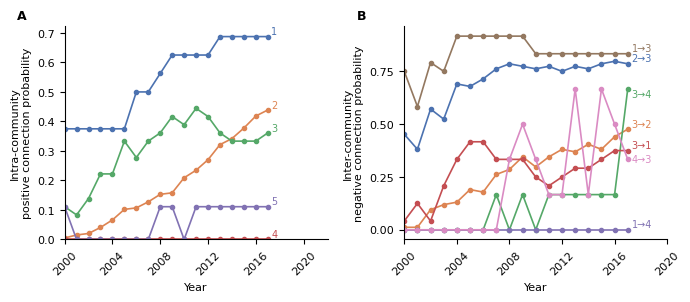

In [7]:
# Combined figure (pos28): A — within-community positive density; B — inter-community negative probability
cm = 1/2.54
pal = sns.color_palette('deep')

# Sizes depend on how many of the 28 countries fall in each community
comm_labels_p28 = [f'{ic+1}' for ic in range(nc_p28)]
comm_va_p28 = ['bottom'] * nc_p28  # adjust if lines overlap after running

years_b = np.arange(syear_b, eyear_b + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(17.8*cm, 8*cm))

for ax, label in zip([ax1, ax2], ['A', 'B']):
    ax.text(-0.18, 1.08, label, transform=ax.transAxes,
            fontsize=9, fontweight='bold', va='top', ha='left')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.tick_params(axis='both', labelsize=8)
    ax.xaxis.set_major_locator(plt.MultipleLocator(4))
    ax.tick_params(axis='x', rotation=45)

# --- A: Within-community positive density ---
for ic in range(nc_p28):
    ax1.plot(years_b, pblock_p28[:, ic, ic],
             'o-', color=pal[ic], linewidth=1.2, markersize=3)
    ax1.text(eyear_b + 0.3, pblock_p28[-1, ic, ic],
             comm_labels_p28[ic], ha='left', va=comm_va_p28[ic], color=pal[ic], fontsize=7)
ax1.set_xlabel('Year', fontsize=8)
ax1.set_ylabel('Intra-community\npositive connection probability', fontsize=8)
ax1.set_ylim(bottom=0)
ax1.set_xlim(syear_b, eyear_b + 5)

# --- B: Inter-community negative connection probability ---
comm_pairs = [(1, 2), (2, 1), (2, 3), (2, 0), (0, 3), (0, 2), (3, 2)]
comm_pairs = [(ic, jc) for ic, jc in comm_pairs if ic < nc_p28 and jc < nc_p28]
for i, (ic, jc) in enumerate(comm_pairs):
    ax2.plot(years_b, nblock_p28[:, ic, jc],
             'o-', lw=1.2, color=pal[i], markersize=3)
    va = 'top' if (ic, jc) in [(3, 0), (2, 3)] else ('center' if (ic, jc) == (3, 2) else 'bottom')
    ax2.text(eyear_b + 0.3, nblock_p28[-1, ic, jc],
             f'{ic+1}→{jc+1}', ha='left', va=va, color=pal[i], fontsize=7)
ax2.set_xlabel('Year', fontsize=8)
ax2.set_ylabel('Inter-community\nnegative connection probability', fontsize=8)
ax2.set_yticks([0, 0.25, 0.5, 0.75])
ax2.set_xlim(syear_b, eyear_b + 3)

plt.tight_layout()
plt.savefig(os.path.join(path2figures, 'FigSI_community_pos28.pdf'), dpi=300, bbox_inches='tight')
plt.show()


## Source Data for Supplementary Figs. S15 and S17

The values plotted, written to `Source Data/SourceData_FigS15.xlsx` and `SourceData_FigS17.xlsx`.

In [8]:
from sourcedatautils import write_source_data

write_source_data('SourceData_FigS15.xlsx', 'Supplementary Figure 15: Dynamic new-edge decomposition.',
                  'Share of the new positive (A) and negative (B) edges in each year between existing and new countries.',
                  [('S15', 'New-edge decomposition in each year.', new_edge_decomp)])

s17a = pd.DataFrame([[y, ic + 1, pblock_p28[iy, ic, ic]] for iy, y in enumerate(years_b) for ic in range(nc_p28)],
                    columns=['Year', 'Community', 'Positive connection probability within the community'])
s17b = pd.DataFrame([[y, ic + 1, jc + 1, nblock_p28[iy, ic, jc]] for iy, y in enumerate(years_b) for ic, jc in comm_pairs],
                    columns=['Year', 'Source community', 'Target community', 'Negative connection probability'])
write_source_data('SourceData_FigS17.xlsx', 'Supplementary Figure 17: Increasing within-community cohesion and persistent between-community separation.',
                  ('Restricted to the fixed set of countries observable in 2000. A) Probability of a positive citation '
                   'preference within each community; B) probability of a negative citation preference between pairs of '
                   'communities (communities numbered as in Fig. 2).'),
                  [('S17 A', 'Within-community positive connection probability in each year.', s17a),
                   ('S17 B', 'Between-community negative connection probability in each year.', s17b)])

wrote /Users/psp2nq/Documents/NationalBiasCode/Source Data/SourceData_FigS15.xlsx
wrote /Users/psp2nq/Documents/NationalBiasCode/Source Data/README.txt
wrote /Users/psp2nq/Documents/NationalBiasCode/Source Data/SourceData_FigS17.xlsx
wrote /Users/psp2nq/Documents/NationalBiasCode/Source Data/README.txt
